# Medical Insurance High-Cost Risk Prediction

**End-to-end Data Science case study:** Business question → Data Loading → Data Quality → EDA → Feature Engineering → Data Splitting → Model Training → Evaluation → Explainability → Business Recommendations.

**Research question:** Given demographic and lifestyle-related attributes from an educational medical insurance dataset, can we estimate whether the recorded medical charge is **at least $20,000**? This is binary classification, **not** a prediction of an exact dollar bill or a future insurance claim.

The original public CSV contains **1,338 observations**. Its source is listed in the repository README. This is an independent learning portfolio exercise, not an employer project.

**How to use this notebook:** Open from any working directory with the project folders intact and run **Kernel → Restart & Run All**. Charts below are generated from real data by their own Python cells and are embedded in this notebook for GitHub preview.

### Key findings and evaluation protocol

- Explore medical charges and associated features on the **deduplicated** public dataset; run the following cells for exact group metrics.
- Training/test split: stratified 80/20, random seed 42. The 20% holdout is not used for model selection.
- Model selection: highest training-only 5-fold mean ROC-AUC; marginal CV differences should not be treated as proof of superiority.
- Sensitivity: 20 additional overlapping stratified holdouts, descriptive only (not external validation or confidence intervals).
- SHAP describes model associations, not causal drivers. Demographic inputs raise fairness concerns; this is a teaching case study, not a production risk score.


## 1. Environment Setup and Data Loading

We first resolve the project root so the notebook works whether Jupyter starts from the project directory or the `notebooks/` folder. We then load the CSV, inspect the first observations, and print field types.

In [1]:
from pathlib import Path
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image

# Resolve the repository root without assuming the Jupyter working directory.
candidates = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]
ROOT = next((p for p in candidates if (p / 'src' / 'pipeline.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Project source folder not found. Open this notebook from the repository or notebooks/ folder')
ROOT = ROOT.resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
FIGURES = ROOT / 'reports' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
from src.pipeline import validate_raw, engineer, make_target, HIGH_COST_USD, SEED
from src.train import build_models, cross_validate_auc, evaluate
from sklearn.model_selection import train_test_split
from sklearn.base import clone

plt.rcParams.update({'figure.figsize': (9, 5), 'figure.dpi': 110, 'savefig.dpi': 160, 'axes.spines.top': False, 'axes.spines.right': False})
sns.set_theme(style='whitegrid', font_scale=0.93)
from src.data import ensure_dataset
data_file = ensure_dataset(ROOT / 'data' / 'insurance.csv')   # downloads the public CSV on first run and verifies its checksum
raw_input = pd.read_csv(data_file)
raw = raw_input.copy()
print('Dataset shape:', raw.shape)
print('Columns:', ', '.join(raw.columns))
display(raw.head(8))
print('Column types:')
print(raw.dtypes.to_string())

Dataset shape: (1338, 7)
Columns: age, sex, bmi, children, smoker, region, charges


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
5,31,female,25.740,0,no,southeast,3756.62160
6,46,female,33.440,1,no,southeast,8240.58960
7,37,female,27.740,3,no,northwest,7281.50560


Column types:
age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64


## 2. Data Quality & Cleaning

Before modeling, we check missing cells, exact duplicate rows, numeric plausibility and allowed categories. Exact duplicates are removed before EDA and the first training split. The validation function refuses invalid inputs rather than silently changing them. We retain duplicate records during this educational analysis because an identical row may represent more than one observation; whether to deduplicate must be justified by record identifiers, which the dataset lacks.

In [2]:
print('Missing by column:')
display(raw.isna().sum().rename('missing_count').to_frame())
print('Exact duplicate rows:', raw.duplicated().sum())
print('Numeric summaries:')
display(raw.describe().round(2))
print('Categorical frequencies:')
for col in ['sex', 'smoker', 'region']:
    print(f'\n{col}:')
    display(raw[col].value_counts(dropna=False).rename('count').to_frame())
from src.pipeline import clean_training_data
raw, duplicate_count = clean_training_data(raw)
print(f'Exact duplicates removed before EDA, training and evaluation: {duplicate_count}')
print('Validation successful. Unique records retained:', len(raw))

Missing by column:


,missing_count
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


Exact duplicate rows: 1
Numeric summaries:


,age,bmi,children,charges
count,1338.00,1338.00,1338.00,1338.00
mean,39.21,30.66,1.09,13270.42
std,14.05,6.10,1.21,12110.01
min,18.00,15.96,0.00,1121.87
25%,27.00,26.30,0.00,4740.29
50%,39.00,30.40,1.00,9382.03
75%,51.00,34.69,2.00,16639.91
max,64.00,53.13,5.00,63770.43


Categorical frequencies:

sex:


,count
sex,
male,676
female,662



smoker:


,count
smoker,
no,1064
yes,274



region:


,count
region,
southeast,364
southwest,325
northwest,325
northeast,324


Exact duplicates removed before EDA, training and evaluation: 1
Validation successful. Unique records retained: 1337


## 3. Exploratory Data Analysis (EDA)

This section answers concrete questions using plots generated from the underlying dataset, not static placeholders. The visualizations are **descriptive**, and group associations do not prove causation.

### 3.1 Distribution of medical charges

We examine the skew, spread, outliers and position of the **illustrative $20,000 threshold**. A histogram and box plot show why classification is a reasonable teaching exercise.

Median charge ($): 9386.16
Mean charge ($): 13279.12
Share >= $20,000: 20.4%


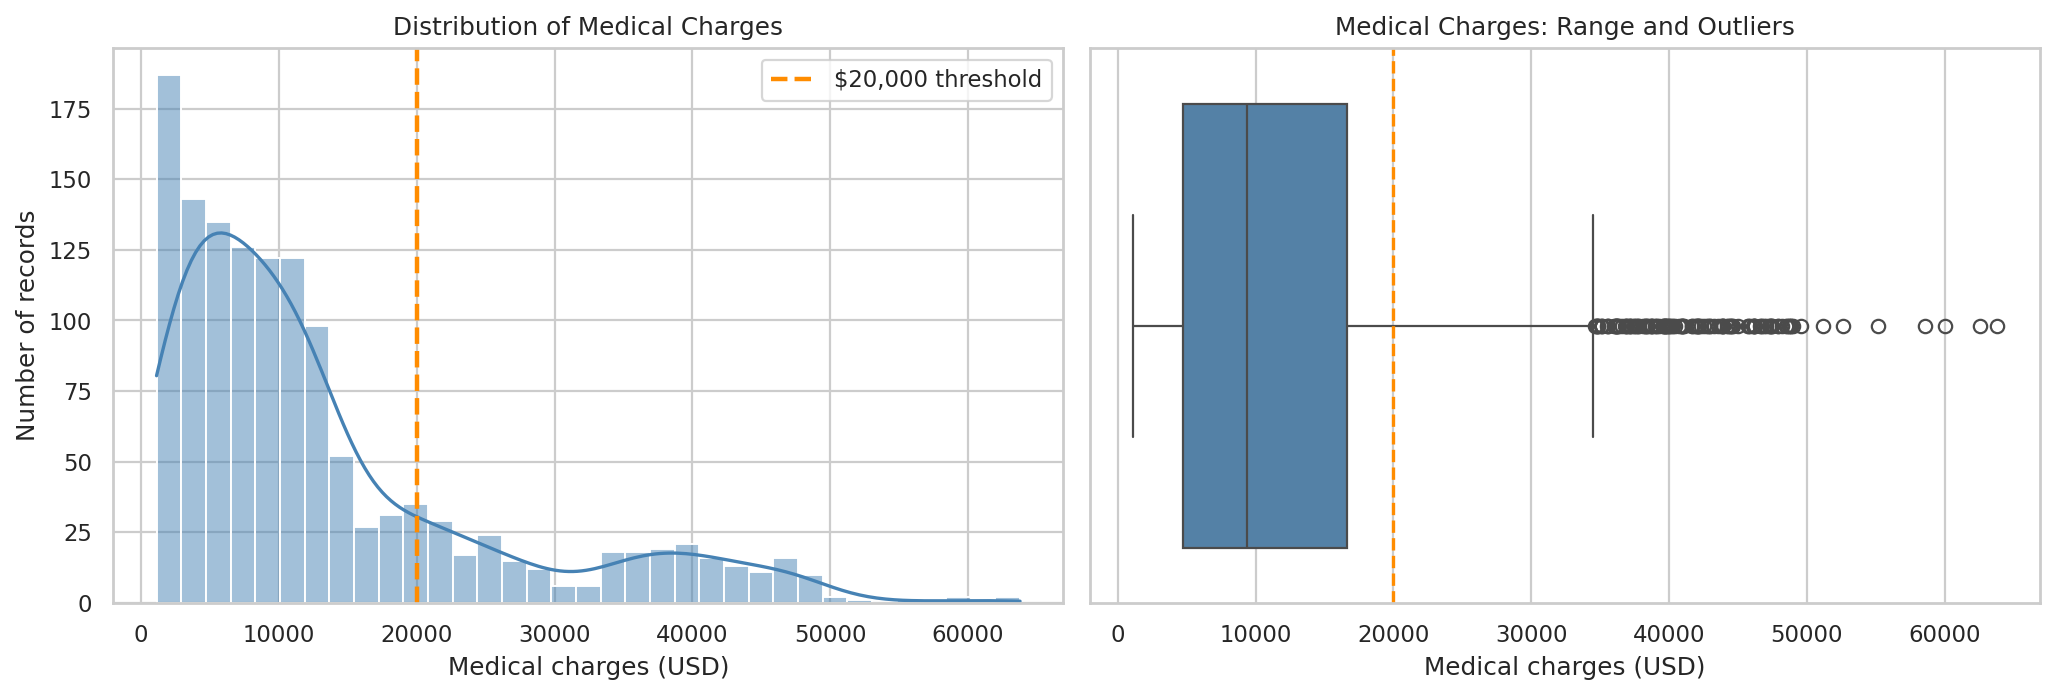

In [3]:
plt.close('all')
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=raw, x='charges', bins=35, kde=True, color='steelblue', ax=axes[0])
axes[0].axvline(HIGH_COST_USD, color='darkorange', linewidth=2, linestyle='--', label='$20,000 threshold')
axes[0].set(title='Distribution of Medical Charges', xlabel='Medical charges (USD)', ylabel='Number of records')
axes[0].legend()
sns.boxplot(data=raw, x='charges', color='steelblue', ax=axes[1])
axes[1].axvline(HIGH_COST_USD, color='darkorange', linestyle='--')
axes[1].set(title='Medical Charges: Range and Outliers', xlabel='Medical charges (USD)')
fig.tight_layout()
fig.savefig(FIGURES / 'eda_01_charges_distribution.png', bbox_inches='tight')
plt.close('all')
print('Median charge ($):', round(raw.charges.median(), 2))
print('Mean charge ($):', round(raw.charges.mean(), 2))
print('Share >= $20,000:', f'{(raw.charges >= HIGH_COST_USD).mean():.1%}')
# Embed the newly generated figure in the saved notebook output.
display(Image(filename=str(FIGURES / "eda_01_charges_distribution.png")))


**EDA finding:** Annual medical charges are right-skewed; a high-cost minority accounts for a substantial share of the total. See the computed counts and percentages in §3.8.


### 3.2 Smoking status and medical charges

Compare the distribution of charges across smoking-status groups. This does **not** establish whether smoking causes an observed expense difference; the data are observational and lack many potentially relevant factors.

,count,median,mean
smoker,,,
no,1063,7345.73,8440.66
yes,274,34456.35,32050.23


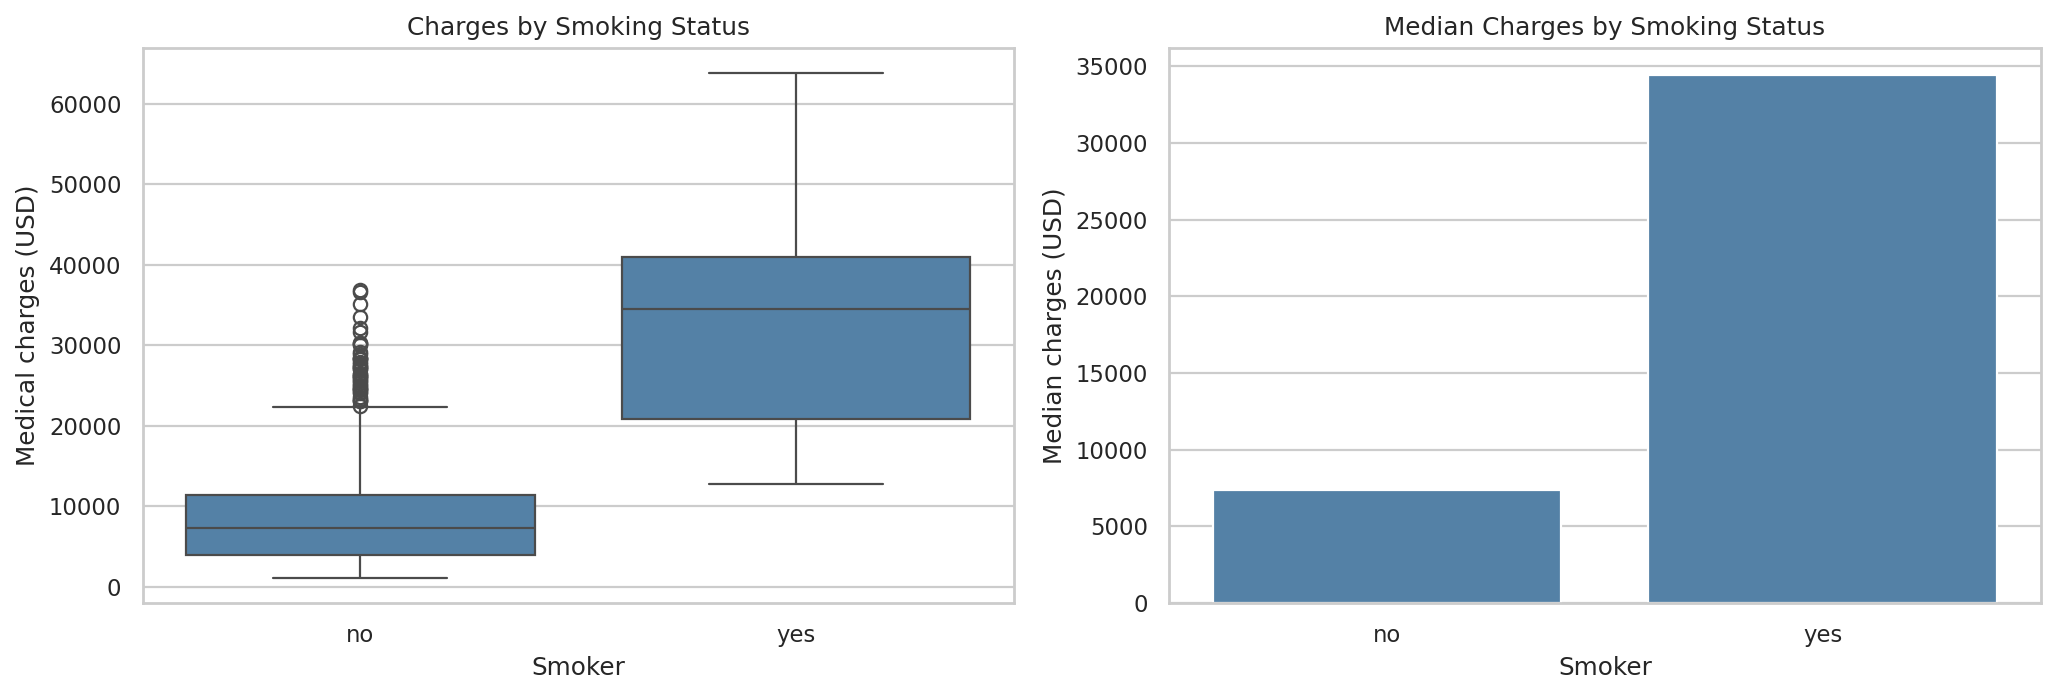

In [4]:
plt.close('all')
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=raw, x='smoker', y='charges', ax=axes[0], order=['no', 'yes'], color='steelblue')
axes[0].set(title='Charges by Smoking Status', xlabel='Smoker', ylabel='Medical charges (USD)')
sns.barplot(data=raw, x='smoker', y='charges', estimator='median', errorbar=None, order=['no','yes'], color='steelblue', ax=axes[1])
axes[1].set(title='Median Charges by Smoking Status', xlabel='Smoker', ylabel='Median charges (USD)')
fig.tight_layout()
fig.savefig(FIGURES / 'eda_02_smoking.png', bbox_inches='tight')
plt.close('all')
display(raw.groupby('smoker')['charges'].agg(['count', 'median', 'mean']).round(2))
# Embed the newly generated figure in the saved notebook output.
display(Image(filename=str(FIGURES / "eda_02_smoking.png")))


**EDA finding:** Smoking status is strongly associated with higher charges in this dataset; compare the precise median values and shares calculated in §3.8. These are observational associations, not causal effects.


### 3.3 Age vs. charges

A scatter plot exposes the relationship between the continuous predictor `age` and the recorded charge, with color indicating smoking status. We use it to detect groups and nonlinear patterns.

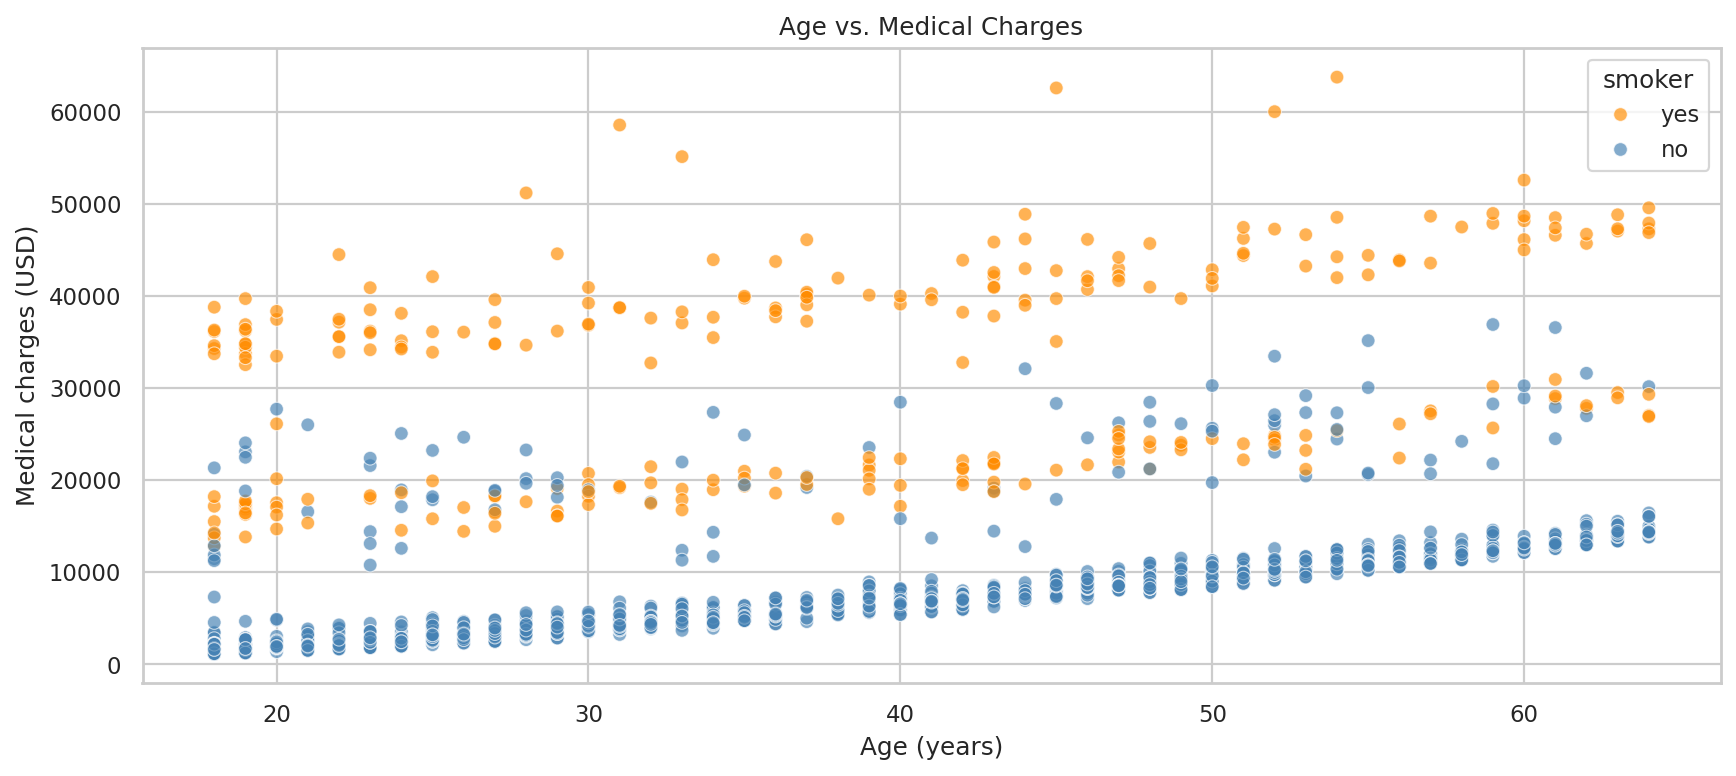

In [5]:
plt.close('all')
fig, ax = plt.subplots(figsize=(11, 5))
sns.scatterplot(data=raw, x='age', y='charges', hue='smoker', alpha=0.67, s=38, palette={'yes':'darkorange','no':'steelblue'}, ax=ax)
ax.set(title='Age vs. Medical Charges', xlabel='Age (years)', ylabel='Medical charges (USD)')
fig.tight_layout()
fig.savefig(FIGURES / 'eda_03_age_vs_charges.png', bbox_inches='tight')
plt.close('all')
# Embed the newly generated figure in the saved notebook output.
display(Image(filename=str(FIGURES / "eda_03_age_vs_charges.png")))


**EDA finding:** The age/charges association differs across smoking groups in the plot. This dataset alone cannot establish why.


### 3.4 BMI vs. charges

BMI is the body mass index. Inspect the observed relationship with charges and whether the visual pattern differs by smoking group. We also show the BMI ≥ 30 indicator used later in feature engineering.

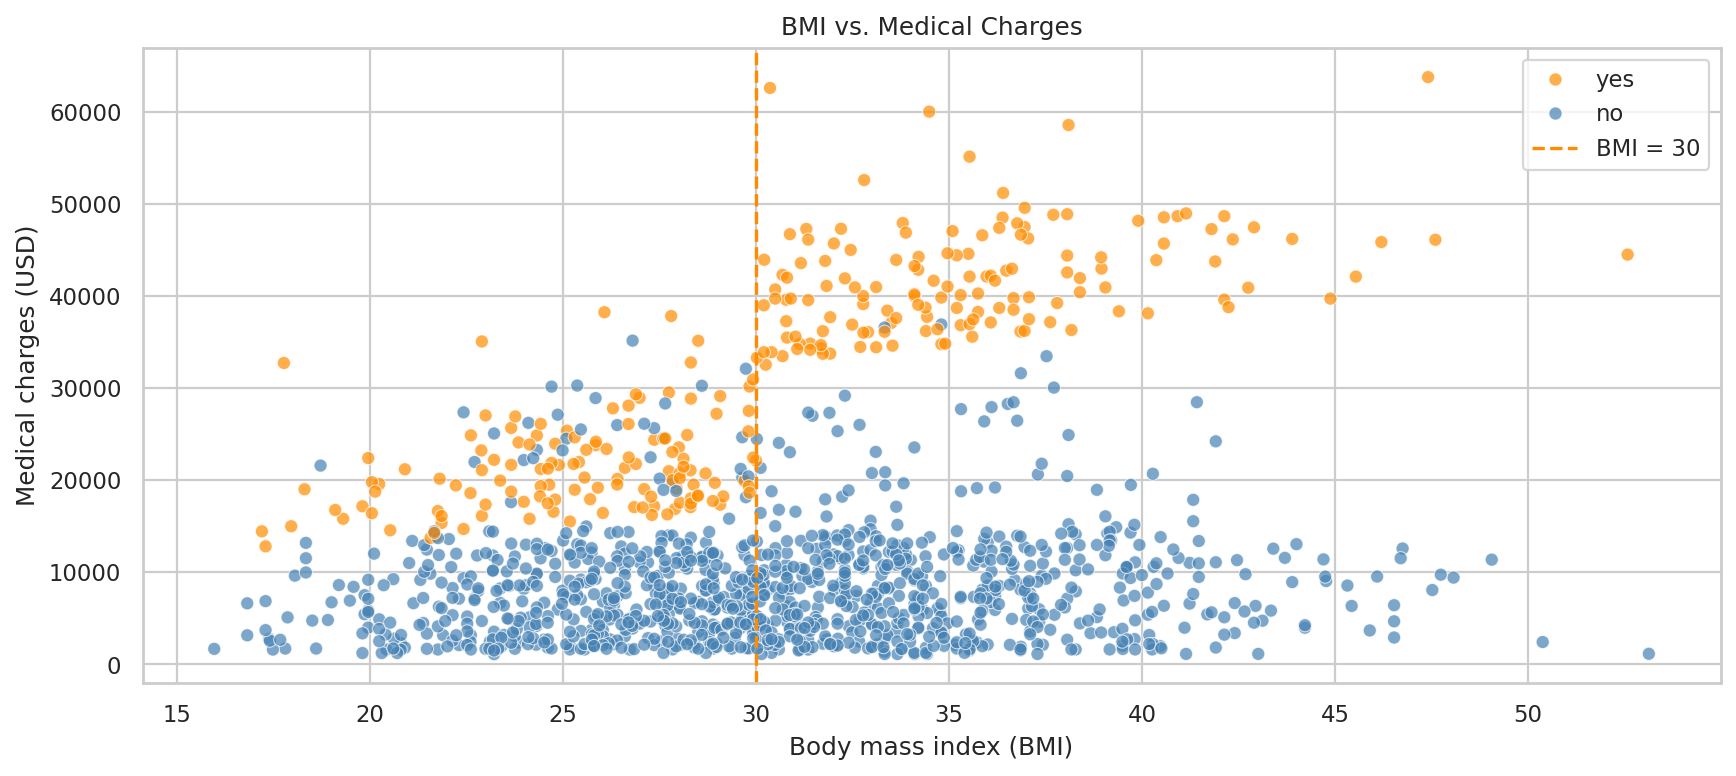

In [6]:
plt.close('all')
fig, ax = plt.subplots(figsize=(11, 5))
sns.scatterplot(data=raw, x='bmi', y='charges', hue='smoker', alpha=0.70, s=35, palette={'yes':'darkorange','no':'steelblue'}, ax=ax)
ax.axvline(30, color='darkorange', linestyle='--', linewidth=1.5, label='BMI = 30')
ax.set(title='BMI vs. Medical Charges', xlabel='Body mass index (BMI)', ylabel='Medical charges (USD)')
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / 'eda_04_bmi_vs_charges.png', bbox_inches='tight')
plt.close('all')
# Embed the newly generated figure in the saved notebook output.
display(Image(filename=str(FIGURES / "eda_04_bmi_vs_charges.png")))


**EDA finding:** Compare BMI patterns within each smoking group; §3.8 prints exact high-cost rates for each segment.


### 3.5 Region and children

Plot median charges by geographic region and by number of children. These are **unadjusted** comparisons and should not be interpreted as causal effects or a basis for discriminatory decisions.

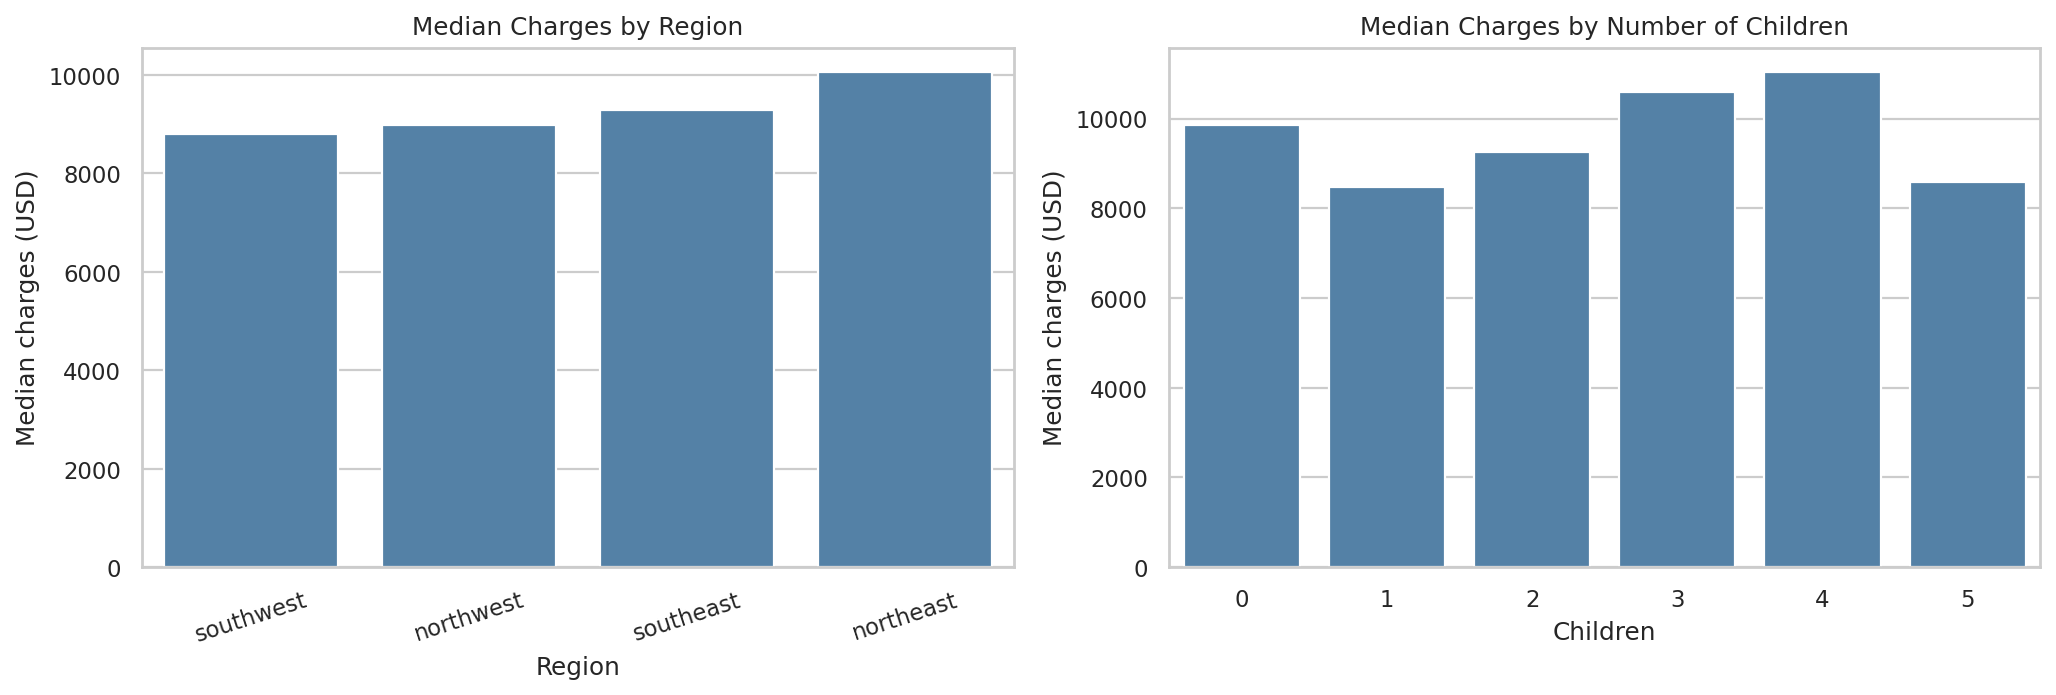

In [7]:
plt.close('all')
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
region_order = raw.groupby('region')['charges'].median().sort_values().index
sns.barplot(data=raw, x='region', y='charges', order=region_order, estimator='median', errorbar=None, color='steelblue', ax=axes[0])
axes[0].set(title='Median Charges by Region', xlabel='Region', ylabel='Median charges (USD)')
axes[0].tick_params(axis='x', rotation=18)
sns.barplot(data=raw, x='children', y='charges', estimator='median', errorbar=None, color='steelblue', ax=axes[1])
axes[1].set(title='Median Charges by Number of Children', xlabel='Children', ylabel='Median charges (USD)')
fig.tight_layout()
fig.savefig(FIGURES / 'eda_05_region_children.png', bbox_inches='tight')
plt.close('all')
# Embed the newly generated figure in the saved notebook output.
display(Image(filename=str(FIGURES / "eda_05_region_children.png")))


**EDA finding:** Region and number-of-children medians differ across groups, but these are raw descriptive differences without confounder adjustment; exact values appear in §3.8.


### 3.6 High-cost class balance and group prevalence

Define the illustrative target from `charges` using a fixed threshold and visualize the class balance. Compare the *observed* share of high-cost labels by smoking status and region. This is useful for understanding class imbalance before evaluating Precision, Recall and PR-AUC.

,count
high_cost,
0,1064
1,273


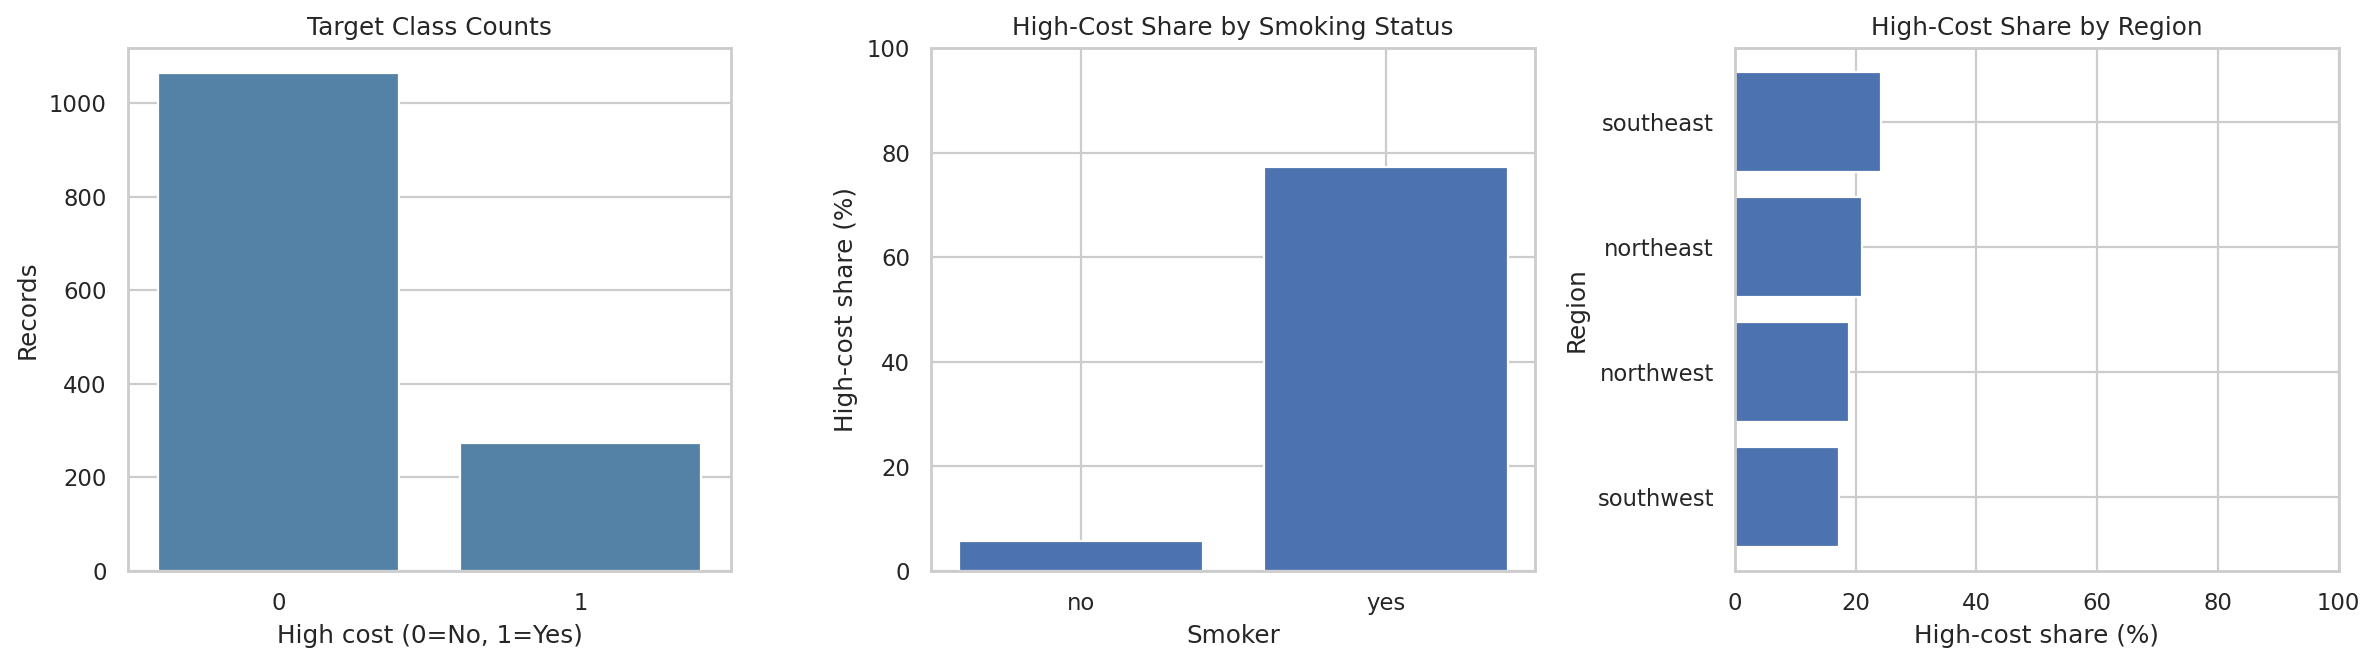

In [8]:
plt.close('all')
eda = raw.copy()
eda['high_cost'] = make_target(eda['charges'])
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
sns.countplot(data=eda, x='high_cost', color='steelblue', ax=axes[0])
axes[0].set(title='Target Class Counts', xlabel='High cost (0=No, 1=Yes)', ylabel='Records')
by_smoker = (eda.groupby('smoker')['high_cost'].mean()*100).reindex(['no','yes'])
axes[1].bar(by_smoker.index, by_smoker.values)
axes[1].set(title='High-Cost Share by Smoking Status', xlabel='Smoker', ylabel='High-cost share (%)', ylim=(0,100))
by_region = (eda.groupby('region')['high_cost'].mean()*100).sort_values()
axes[2].barh(by_region.index, by_region.values)
axes[2].set(title='High-Cost Share by Region', xlabel='High-cost share (%)', ylabel='Region', xlim=(0,100))
fig.tight_layout()
fig.savefig(FIGURES / 'eda_06_high_cost_segments.png', bbox_inches='tight')
plt.close('all')
display(eda['high_cost'].value_counts().rename_axis('high_cost').to_frame('count'))
# Embed the newly generated figure in the saved notebook output.
display(Image(filename=str(FIGURES / "eda_06_high_cost_segments.png")))


**EDA finding:** High-cost records form a minority class. We report PR-AUC, recall and Brier score alongside ROC-AUC. Segment rates depend on the fixed illustrative cutoff.


### 3.7 Numerical feature correlations

Inspect the **linear** correlations among recorded numeric inputs and charges. Correlation does not establish a cause; one-hot encoded category contributions are examined in the later model section.

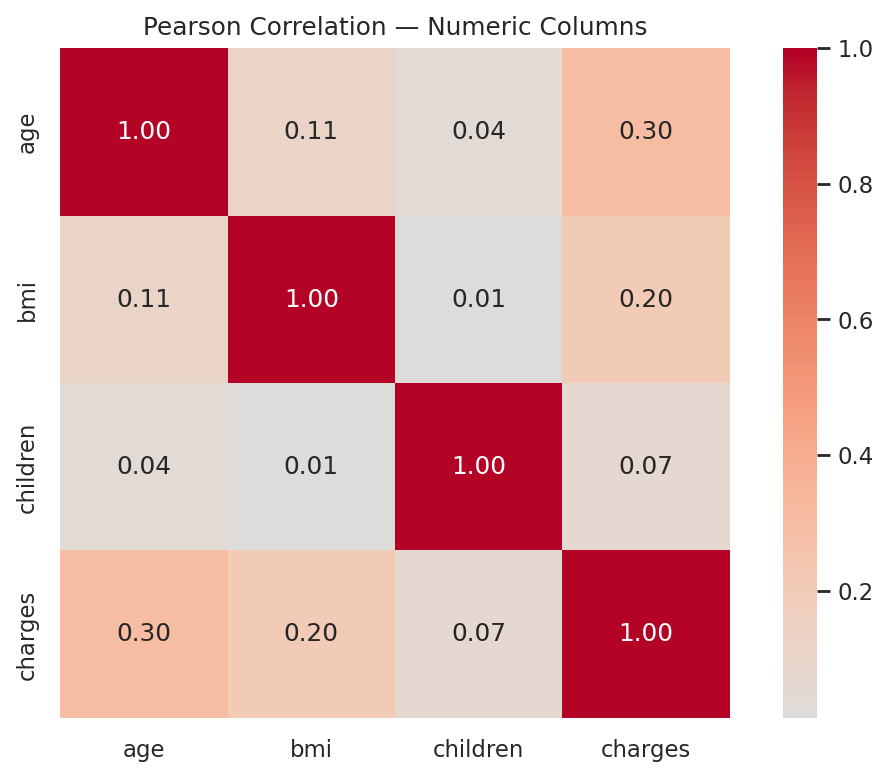

In [9]:
plt.close('all')
num = raw[['age','bmi','children','charges']]
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(num.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, ax=ax)
ax.set_title('Pearson Correlation — Numeric Columns')
fig.tight_layout()
fig.savefig(FIGURES / 'eda_07_numeric_correlation.png', bbox_inches='tight')
plt.close('all')
# Embed the newly generated figure in the saved notebook output.
display(Image(filename=str(FIGURES / "eda_07_numeric_correlation.png")))


### 3.8 Key numbers behind the EDA findings

The findings above are summarised here with exact figures, so every statement can be checked.

In [10]:
hc = make_target(raw["charges"]) == 1
medians = raw.groupby("smoker")["charges"].median()
print(f"Median charges: non-smokers ${medians['no']:,.0f} vs smokers ${medians['yes']:,.0f}")
print(f"High-cost records: {hc.sum()} of {len(raw)} ({hc.mean():.1%}); they generate {raw.loc[hc, 'charges'].sum() / raw['charges'].sum():.1%} of total charges")
print(f"Share of high-cost records that are smokers: {raw.loc[hc, 'smoker'].eq('yes').mean():.1%}")

segments = (raw.assign(high_cost=hc.astype(int), bmi_group=np.where(raw["bmi"] >= 30, "BMI >= 30", "BMI < 30"))
              .groupby(["smoker", "bmi_group"])["high_cost"].agg(["mean", "size"]))
segments["mean"] = (segments["mean"] * 100).round(1)
display(segments.rename(columns={"mean": "high-cost rate (%)", "size": "records"}))

age_band = pd.cut(raw["age"], [17, 29, 39, 49, 64], labels=["18-29", "30-39", "40-49", "50-64"])
by_age = (raw.assign(high_cost=hc.astype(int)).groupby([age_band, "smoker"], observed=True)["high_cost"].mean().unstack() * 100).round(1)
display(by_age.rename(columns={"no": "non-smoker (%)", "yes": "smoker (%)"}))

print("Median charges by region:", raw.groupby("region")["charges"].median().round(0).astype(int).to_dict())
print("Median charges by number of children:", raw.groupby("children")["charges"].median().round(0).astype(int).to_dict())

Median charges: non-smokers $7,346 vs smokers $34,456
High-cost records: 273 of 1337 (20.4%); they generate 52.3% of total charges
Share of high-cost records that are smokers: 77.7%


high-cost rate (%)  records
smoker bmi_group                             
no     BMI < 30                  5.8      502
       BMI >= 30                 5.7      561
yes    BMI < 30                 51.9      129
       BMI >= 30               100.0      145

smoker,non-smoker (%),smoker (%)
age,,
18-29,4.2,55.8
30-39,2.5,70.7
40-49,4.6,88.7
50-64,10.1,100.0


Median charges by region: {'northeast': 10058, 'northwest': 8977, 'southeast': 9294, 'southwest': 8799}
Median charges by number of children: {0: 9863, 1: 8484, 2: 9265, 3: 10601, 4: 11034, 5: 8590}


**EDA summary:** We inspected distribution shape, observed group differences, age/BMI patterns, class balance, and correlations. Next, we define the prediction target and create input features **without exposing the observed `charges` column to the classifier**.

## 4. Target Definition & Leakage Prevention

`high_cost` is defined with a **fixed, round-number cutoff of $20,000** (about the 80th percentile of this dataset, so roughly 20% of records are labelled high-cost). It is an illustration, not an actuarial standard. Crucially, the original `charges` column is never used as a model input: it only defines the label.

In [11]:
target = make_target(raw["charges"])
features = engineer(raw)
print("Illustrative high-cost threshold (USD):", HIGH_COST_USD)
print("Label distribution:", target.value_counts().to_dict())
print("Predictor columns:", list(features.columns))
assert "charges" not in features.columns

Illustrative high-cost threshold (USD): 20000.0
Label distribution: {0: 1064, 1: 273}
Predictor columns: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'obese', 'smoker_obese', 'age_smoker']


## 5. Stratified Train/Test Split (No Time Variable)

The dataset has no time column, so we use a **stratified random 80/20 split**. The 20% holdout is excluded from cross-validation and model selection.

In [12]:
from src.pipeline import SEED
X_train, X_test, y_train, y_test = train_test_split(
    features, target, test_size=0.20, random_state=SEED, stratify=target
)
print("Train:",X_train.shape,"Holdout:",X_test.shape)

Train: (1069, 9) Holdout: (268, 9)


## 6. Model Training & Five-Fold Cross-Validation

We fit preprocessing within each fold using `Pipeline`, so test and validation records cannot influence scaling or one-hot encoding. We compare Logistic Regression, XGBoost and CatBoost using **training CV ROC-AUC**. The test holdout is not used to choose the winner.

In [13]:
from sklearn.base import clone
models = build_models()
cv_rows = []
for name, model in models.items():
    aucs = cross_validate_auc(model, X_train, y_train, folds=5)
    cv_rows.append({"Model":name,"CV ROC-AUC":aucs.mean(),"CV Std":aucs.std()})
cv_table = pd.DataFrame(cv_rows).sort_values("CV ROC-AUC",ascending=False)
display(cv_table.round(4))
selected_name = cv_table.iloc[0]["Model"]
print("Chosen by training CV:", selected_name)

,Model,CV ROC-AUC,CV Std
2,CatBoost,0.8914,0.0505
0,LogisticRegression,0.8878,0.0523
1,XGBoost,0.8785,0.0491


Chosen by training CV: CatBoost


## 7. Final Holdout Evaluation

Once the training-CV choice is fixed, we evaluate the models on the single holdout. Metrics are ROC-AUC, PR-AUC, Brier score, precision, recall and F1 (at the **fixed 0.50 probability cutoff**, not tuned on the holdout). Test scores must not be used to tune the chosen model.

In [14]:
fitted, test_rows = {}, []
for name, model in models.items():
    fitted[name] = clone(model).fit(X_train,y_train)
    probability = fitted[name].predict_proba(X_test)[:,1]
    test_rows.append({"Model":name,**evaluate(y_test,probability)})
test_table = pd.DataFrame(test_rows)
display(test_table)

,Model,roc_auc,pr_auc,brier,precision,recall,f1
0,LogisticRegression,0.9402,0.9142,0.0345,1.0,0.8545,0.9216
1,XGBoost,0.9472,0.9270,0.0314,1.0,0.8545,0.9216
2,CatBoost,0.9475,0.9231,0.0315,1.0,0.8545,0.9216


**Interpreting holdout:** The chosen algorithm is selected using training-fold CV, not the test split. Compare test metrics with CV and repeated-split sensitivity; a single favourable holdout is not typical performance.


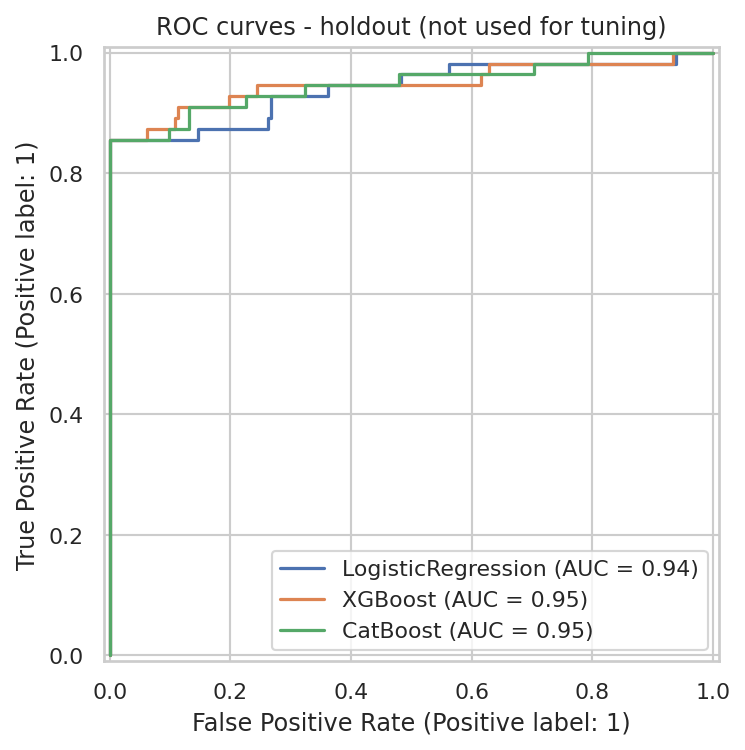

In [15]:
plt.close('all')
from sklearn.metrics import RocCurveDisplay
fig,ax=plt.subplots(figsize=(7,5))
for name,model in fitted.items():
    RocCurveDisplay.from_predictions(y_test,model.predict_proba(X_test)[:,1],name=name,ax=ax)
ax.set_title("ROC curves - holdout (not used for tuning)")
plt.tight_layout();plt.savefig(FIGURES / "roc_curves.png", dpi=155, bbox_inches="tight");plt.close('all')
# Embed the newly generated figure in the saved notebook output.
display(Image(filename=str(FIGURES / "roc_curves.png")))


### 7.1 Model Comparison: Training CV versus final holdout

**Selection rule:** Choose the algorithm by training-only 5-fold cross-validation. Holdout scores are reported once for evaluation, never to choose a winner. The chart below uses the actual computed notebook metrics.

,CV ROC-AUC,Holdout ROC-AUC
Model,,
CatBoost,0.8914,0.9475
LogisticRegression,0.8878,0.9402
XGBoost,0.8785,0.9472


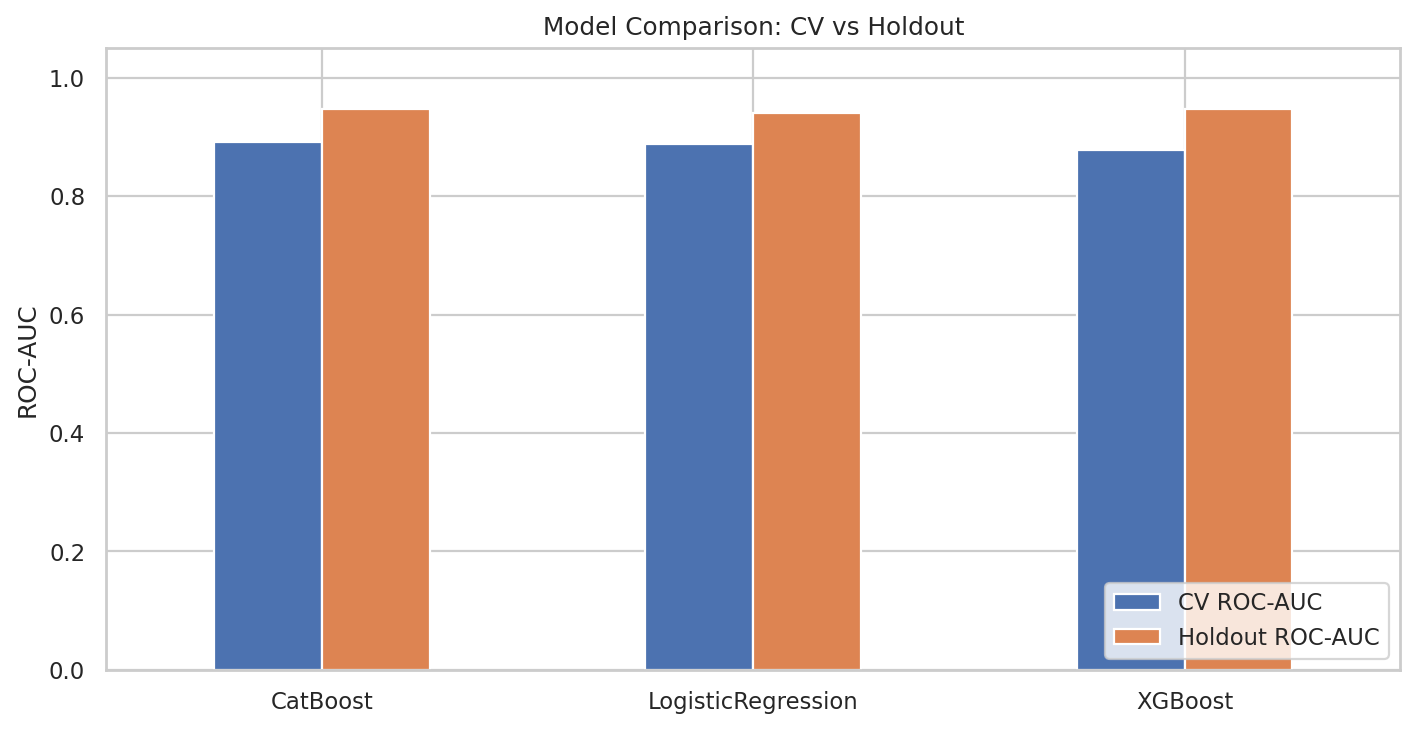

In [16]:
plt.close('all')
comparison = cv_table[['Model', 'CV ROC-AUC']].merge(test_table[['Model', 'roc_auc']], on='Model')
comparison = comparison.rename(columns={'roc_auc': 'Holdout ROC-AUC'}).set_index('Model')
ax = comparison.plot(kind='bar', figsize=(9, 4.7), rot=0)
ax.set(title='Model Comparison: CV vs Holdout', ylabel='ROC-AUC', ylim=(0,1.05), xlabel='')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(FIGURES / 'model_comparison.png', bbox_inches='tight')
plt.close('all')
display(comparison.round(4))
# Embed the newly generated figure in the saved notebook output.
display(Image(filename=str(FIGURES / "model_comparison.png")))


### 7.2 Confusion Matrix of the Selected Model

Use the fixed **0.50 probability threshold** to count true/false positives and negatives on the held-out set. A false negative means a record above the cost threshold was not flagged by the classifier.

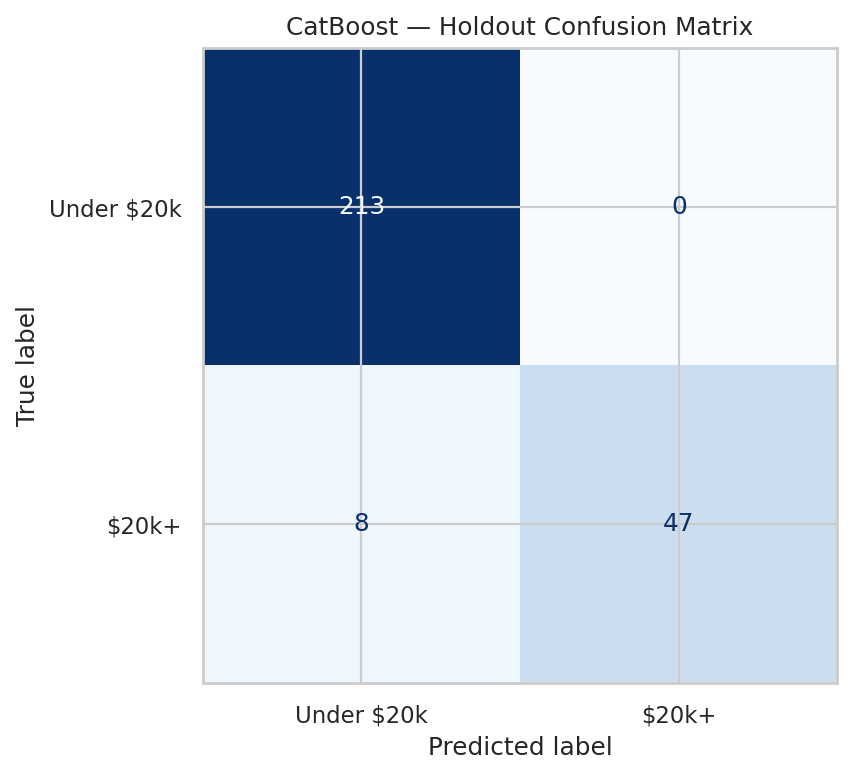

In [17]:
plt.close('all')
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay
p_selected = fitted[selected_name].predict_proba(X_test)[:, 1]
pred_selected = (p_selected >= 0.50).astype(int)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_selected, display_labels=['Under $20k', '$20k+'], ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'{selected_name} — Holdout Confusion Matrix')
fig.tight_layout()
fig.savefig(FIGURES / 'confusion_matrix.png', bbox_inches='tight')
plt.close('all')
# Embed the newly generated figure in the saved notebook output.
display(Image(filename=str(FIGURES / "confusion_matrix.png")))


### 7.3 Precision–Recall Curve

Because the high-cost label is less common, the Precision–Recall curve gives a useful additional view of how many high-cost cases are identified while controlling false alarms.

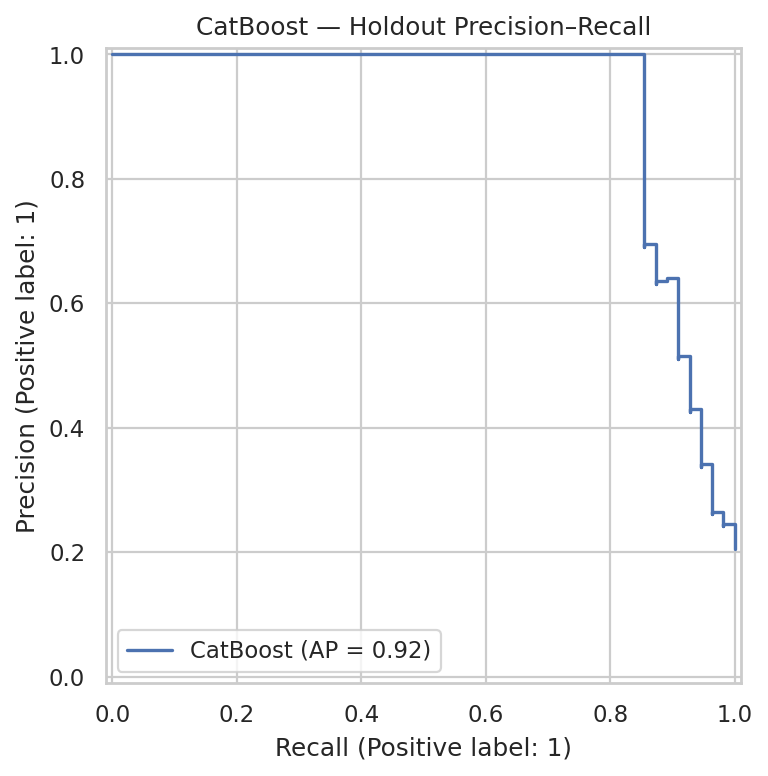

In [18]:
plt.close('all')
fig, ax = plt.subplots(figsize=(7, 5))
PrecisionRecallDisplay.from_predictions(y_test, p_selected, name=selected_name, ax=ax)
ax.set_title(f'{selected_name} — Holdout Precision–Recall')
fig.tight_layout()
fig.savefig(FIGURES / 'precision_recall.png', bbox_inches='tight')
plt.close('all')
# Embed the newly generated figure in the saved notebook output.
display(Image(filename=str(FIGURES / "precision_recall.png")))


In [19]:
# Who does the selected model miss at the fixed 0.50 cutoff? (single holdout split)
holdout_view = X_test.copy()
holdout_view["actual"] = y_test.values
missed = holdout_view[(holdout_view["actual"] == 1) & (p_selected < 0.5)]
false_alarms = holdout_view[(holdout_view["actual"] == 0) & (p_selected >= 0.5)]
print(f"Missed high-cost records: {len(missed)} of {int(holdout_view['actual'].sum())} | of them smokers: {int((missed['smoker'] == 'yes').sum())}")
print(f"False alarms: {len(false_alarms)}")
smokers = holdout_view[holdout_view["smoker"] == "yes"]
print(f"High-cost smokers found: {int(((smokers['actual'] == 1) & (p_selected[(holdout_view['smoker'] == 'yes').to_numpy()] >= 0.5)).sum())} of {int(smokers['actual'].sum())}")

Missed high-cost records: 8 of 55 | of them smokers: 0
False alarms: 0
High-cost smokers found: 47 of 47


**Error analysis (single holdout split):** The preceding cell reports false negatives, false positives and missed cases by smoking status for the actual deduplicated split. Do not generalise a subgroup error count from this small sample.


**Validation interpretation:** The apparent CV vs holdout gap can arise from sampling variation on a small test set. Training-only CV is used for selection; the 20 overlapping holdouts are a descriptive stability check rather than independent validation.


## 8. Explainability

For a tree-based selected model, we explain its transformed model inputs using SHAP. SHAP indicates contributions to model output; it is **not evidence of causal effects**. If Logistic Regression wins, coefficients can be studied instead.

/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


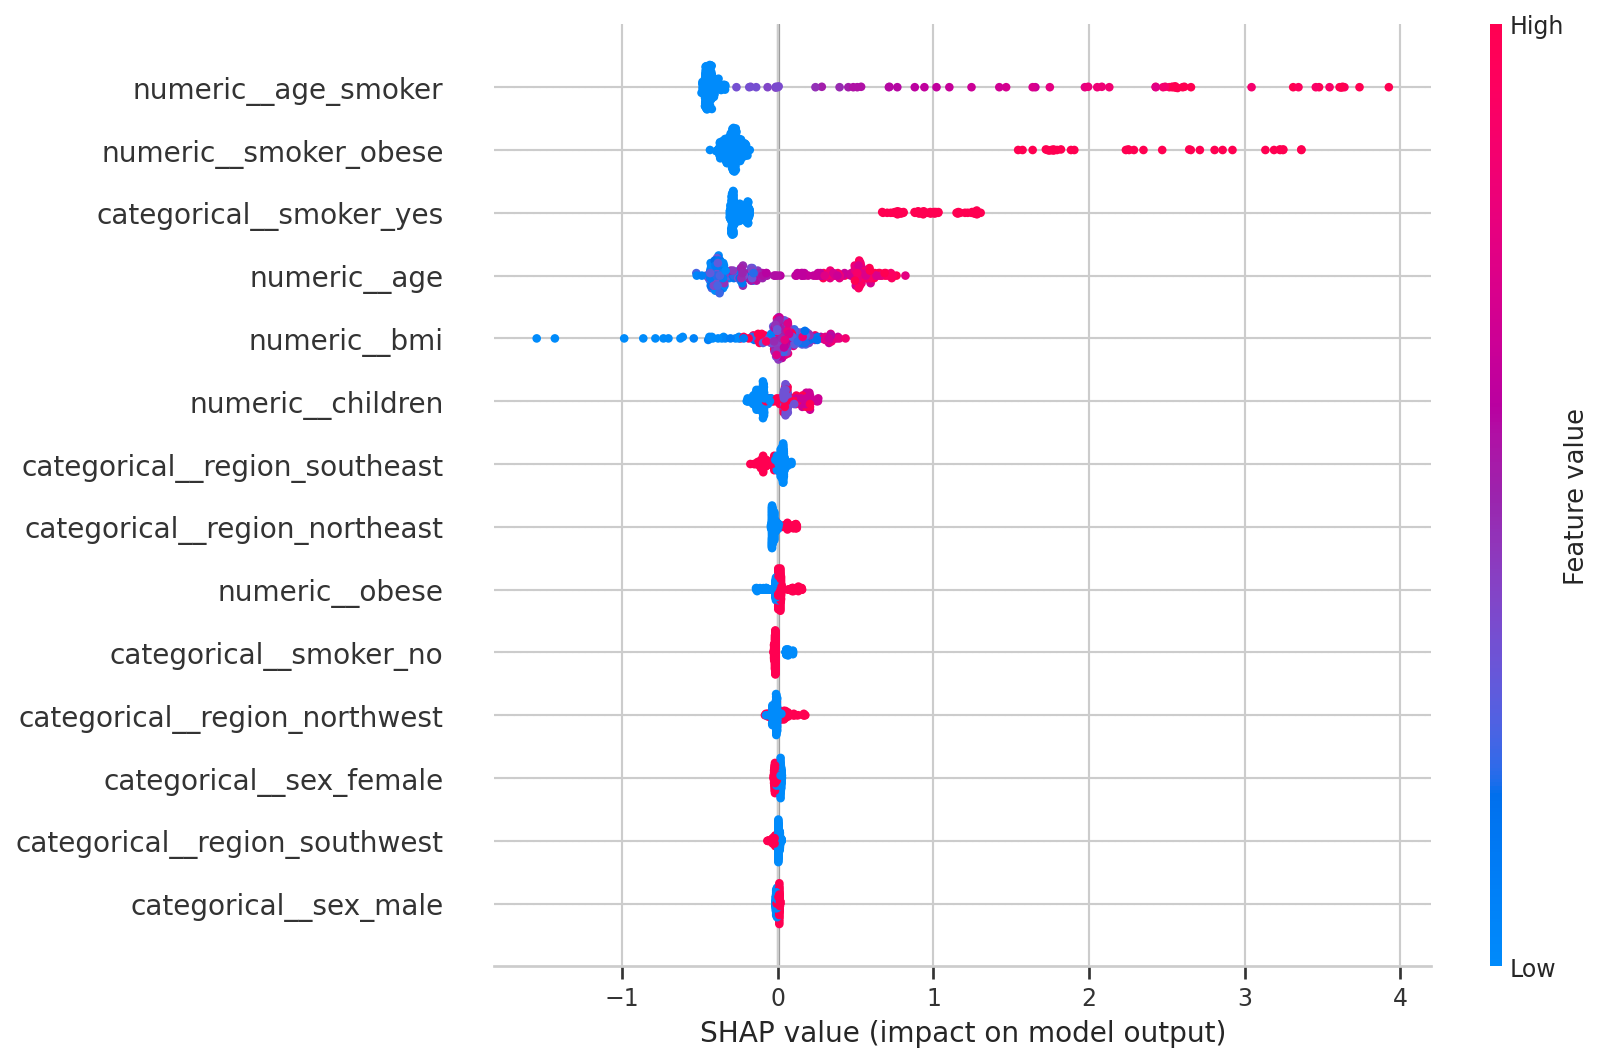

In [20]:
plt.close('all')
if selected_name in {"CatBoost", "XGBoost"}:
    import shap
    selected = fitted[selected_name]
    enc = selected.named_steps["preprocessor"]
    z = enc.transform(X_test)
    values = np.asarray(shap.TreeExplainer(getattr(selected.named_steps["classifier"], "model_", selected.named_steps["classifier"])).shap_values(z))
    if values.ndim == 3:
        values=values[:,:,1]
    plt.figure(figsize=(11, 7))
    shap.summary_plot(values, pd.DataFrame(z,columns=enc.get_feature_names_out()),show=False, plot_size=None)
    plt.tight_layout();plt.savefig(FIGURES / "shap_summary.png", dpi=155, bbox_inches="tight");plt.close('all')
else:
    print("Logistic Regression selected: examine standardized coefficients if needed.")
# Embed the newly generated figure in the saved notebook output.
display(Image(filename=str(FIGURES / "shap_summary.png")))


In [21]:
if selected_name in {"CatBoost", "XGBoost"}:
    shap_names = [n.split("__", 1)[-1] for n in enc.get_feature_names_out()]
    display(pd.Series(np.abs(values).mean(axis=0), index=shap_names)
            .sort_values(ascending=False).head(14).round(3).to_frame("mean |SHAP|"))

,mean |SHAP|
age_smoker,0.740
smoker_obese,0.550
smoker_yes,0.420
age,0.381
bmi,0.139
children,0.104
region_southeast,0.041
region_northeast,0.037
obese,0.032
smoker_no,0.029


**SHAP interpretation:** Inspect the top features and magnitudes printed in the preceding cell. Correlated interactions can share importance, and SHAP values explain the fitted model rather than causal medical effects.


## 9. Prediction Demo

The prediction utility validates incoming values and applies the same training pipeline. The result is an illustrative estimated probability of cost exceeding the cutoff, **not** individualized underwriting advice.

In [22]:
from src.predict import predict_from_rows
example={"age":35,"sex":"female","bmi":27.1,"children":1,"smoker":"no","region":"northeast"}
print(predict_from_rows(fitted[selected_name],[example]))

[{'high_cost_probability': 0.0604, 'high_cost_prediction_at_0_5': 0}]


## 10. Stability Assessment — 20 Stratified Holdouts

A single train/test split can look unusually strong or weak. To assess sensitivity, the following **diagnostic** fits the **already selected CatBoost** on 20 different random 80/20 splits. This does **not** rerun model selection on each split and the test samples overlap. It is not external validation or a formal confidence interval. We report the distribution rather than promising the best single score.

,roc_auc,precision,recall,f1
mean,0.9058,0.9841,0.7664,0.8606
std,0.0272,0.0235,0.0538,0.0363
min,0.8414,0.9091,0.6545,0.7912
max,0.9589,1.0000,0.8545,0.9126


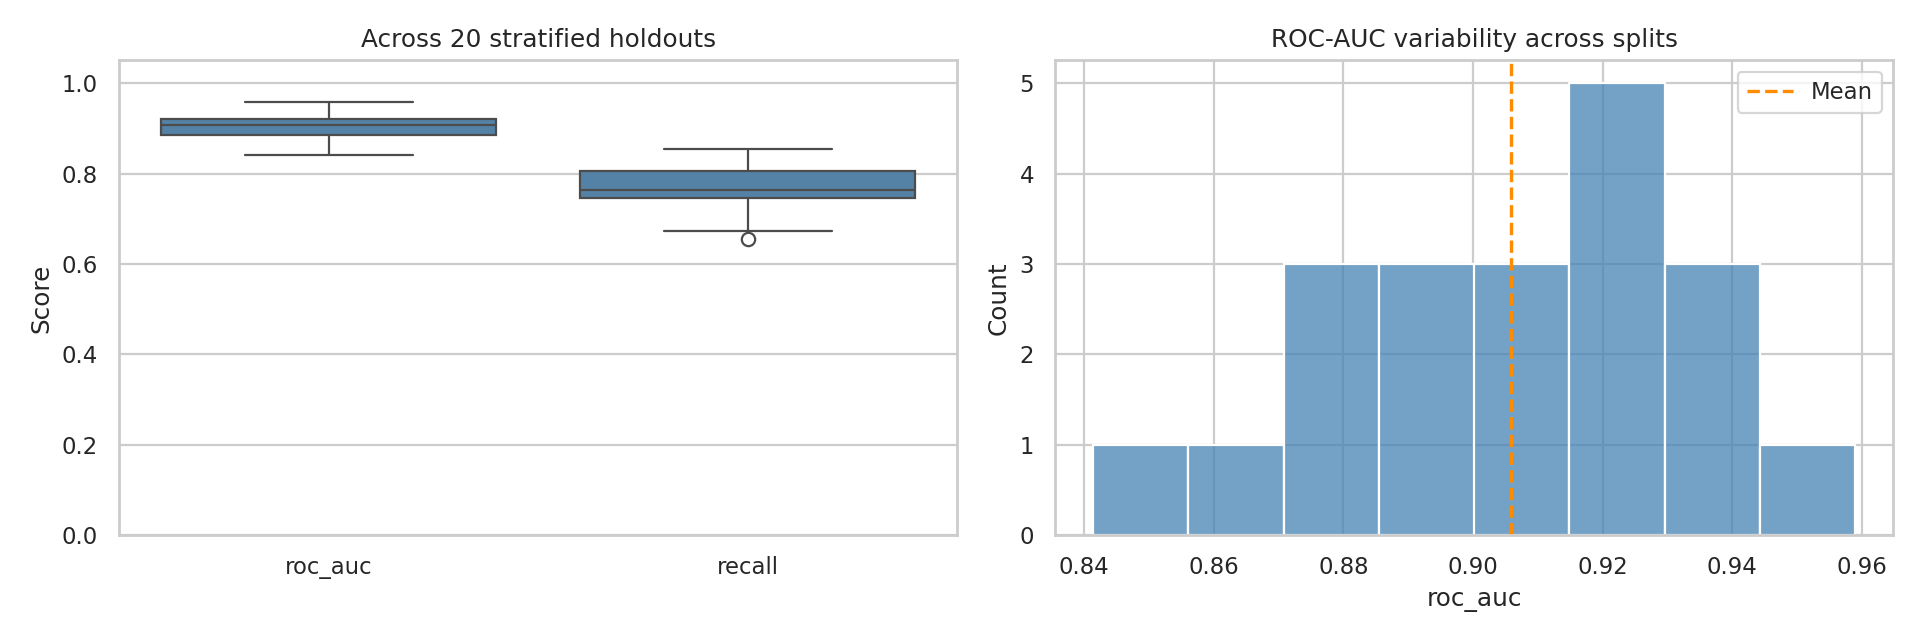

In [23]:
from src.stability import run_stability
stability_rows, stability_summary = run_stability(save_artifacts=False)
display(stability_rows[['roc_auc','precision','recall','f1']].agg(['mean','std','min','max']).round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=stability_rows[['roc_auc','recall']], ax=axes[0], color='steelblue')
axes[0].set_title('Across 20 stratified holdouts')
axes[0].set_ylabel('Score')
axes[0].set_ylim(0, 1.05)
sns.histplot(data=stability_rows, x='roc_auc', bins=8, ax=axes[1], color='steelblue')
axes[1].axvline(stability_rows['roc_auc'].mean(), color='darkorange', ls='--', label='Mean')
axes[1].set_title('ROC-AUC variability across splits')
axes[1].legend()
fig.tight_layout()
fig.savefig(ROOT / 'reports' / 'figures' / 'stability_20_splits.png', dpi=160)
display(Image(filename=str(ROOT / 'reports' / 'figures' / 'stability_20_splits.png')))
plt.close(fig)

**Stability takeaway:** Review the table and variability plot generated directly above. The 20 stratified test splits overlap and are exploratory; do not interpret their spread as a confidence interval.


## 11. Business Value, Interpretation & Limitations

**Business objective:** Estimate the probability that an example individual's medical insurance-related `charges` meet or exceed an **illustrative $20,000 threshold**. This is a binary risk classification, **not** a forecast of an exact future bill, a claim occurrence, a premium, or actual insurer profit.

### How an insurer or broker could use a *validated* model

1. **Portfolio planning:** Explore the proportion of potentially high-cost cases in different cohorts and support scenario discussions. Our classifier alone cannot estimate required reserves in dollars.
2. **Risk monitoring:** Track aggregate risk patterns and investigate where review may be useful, without assuming that model features *cause* the cost differences.
3. **Voluntary preventive care:** With consent and clinical oversight, an insurer might review higher-risk groups for supportive wellness outreach. The model cannot tell whether intervention will work.
4. **Broker context:** A broker could use appropriately aggregated, authorized findings to discuss portfolio trends with insurance partners, but the model does not determine premiums or decide claims.

### Example business decision workflow

- Validate data permissions, representativeness, and input quality.
- Score a cohort and organize records into risk bands for **aggregate analysis**, not automatic adverse decisions.
- Review observations with risk, actuarial, compliance, and healthcare specialists.
- If an intervention is approved, compare a pilot group against an appropriate control group, measuring intervention costs and actual outcomes.

### What success would mean

- **ML quality:** discrimination (ROC-AUC / PR-AUC), calibration (e.g., Brier score), performance across subgroups, and monitoring on later data.
- **Business quality:** improved outreach targeting, better planning decisions, and *measured* net benefit after intervention costs.
- **Not proven here:** financial savings, ROI, reduced medical expenditure, insurer profit, or a real-world intervention effect. No causal/business impact study was run.

### Limitations and responsible use

- Public educational dataset with 1,338 records, few variables, and **no timeline, policy premiums, individual claims history, or follow-up outcomes**.
- The $20,000 boundary is a **predefined illustration**, not an actuarially justified threshold. Generalization to an insurer's own portfolio is untested.
- SHAP describes the model's contributions, **not causal drivers** of cost. Model rankings can change with another cohort.
- Sensitive and demographic proxies require fairness, privacy, legal, clinical, and actuarial assessment before application. **Do not use this demo to deny coverage, price individual policies, adjudicate claims, or direct medical care.**

**Reproducibility:** from the repository root run `python -m pytest -q` and `python -m src.train`; see `README.md`.


### Observed business context from this example dataset

At the illustrative **$20,000** cutoff, a minority of records accounts for a disproportionately large amount of total reported charges. Exact proportions and dollar values are computed in §3.8 on the deduplicated dataset. They are neither verified claims nor measured savings.

The model might illustrate screening for optional follow-up or aggregate monitoring, but any actual deployment requires representative data, proper calibration, fairness assessment, human review, governance and legal approval.


## 12. Portfolio Takeaways

- **Business question:** Identify records above an illustrative $20,000 medical-charge threshold, using only non-target inputs.
- **Data quality:** Validate the schema; remove exact duplicates **before splitting**; preserve the original downloaded CSV unmodified.
- **Modeling:** Use fold-fitted preprocessing, CV-based algorithm selection, held-out performance evaluation, and a separate repeated-split sensitivity assessment.
- **Interpretability and limitations:** Explain correlated feature effects cautiously; do not infer causes or real-world medical/underwriting fitness from this teaching dataset.
- **Reproducibility:** Use the pinned source checksum, executable notebooks, source modules, unit tests and generated reports.
